In [14]:

!pip -q install statsmodels scikit-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, roc_auc_score, classification_report
)
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

In [15]:

uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Saving nvidia_market_analytics.csv to nvidia_market_analytics (2).csv
Dataset shape: (39298, 19)


,Date,Product Category,Product Name,Region,Units Sold,Customer Segment,Customer Type,Customer Satisfaction,Marketing Spend (USD),Discount Percentage (%),Competitor Influence,Return Rate (%),AI/ML Adoption Rate (%),Ad Campaign Effectiveness,Customer Retention Rate (%),Product Launch Date,Competitor Product,Market Share (%),Sales Revenue (USD)
0,2016-08-12,OEM,Tesla T4,Africa,3758.0,Gamers,Individual,1.9,155181.38,8,Low,1.33,12.0,0.22,63.0,2018-10-27,AMD Radeon RX 7900,62.62,3.107797e+08
1,1995-07-02,OEM,Tesla V100,Middle East,4978.0,Cloud Providers,Individual,4.2,136191.16,19,Medium,2.69,75.0,0.28,88.0,2021-07-22,AMD Radeon RX 7900,63.38,2.973832e+08
2,2019-05-08,AI,RTX 4090,Europe,1875.0,AI Researchers,Business,1.3,156854.40,10,Low,4.12,10.0,0.28,80.0,2017-04-18,AMD Radeon RX 7900,69.77,6.043866e+09
3,2008-06-26,OEM,RTX 3080,APAC,3551.0,Cloud Providers,Individual,3.8,79772.88,5,Low,4.69,43.0,0.13,72.0,2001-06-16,Intel Xeon,33.86,2.833449e+08
4,1996-07-17,Gaming,RTX 4090,Europe,1571.0,AI Researchers,Business,4.0,165636.07,15,Medium,0.58,48.0,0.12,63.0,2000-01-04,Google TPU,59.26,2.877546e+08


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39298 entries, 0 to 39297
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Date                         39297 non-null  object 
 1   Product Category             39298 non-null  object 
 2   Product Name                 39296 non-null  object 
 3   Region                       39298 non-null  object 
 4   Units Sold                   39296 non-null  float64
 5   Customer Segment             39296 non-null  object 
 6   Customer Type                39296 non-null  object 
 7   Customer Satisfaction        39297 non-null  float64
 8   Marketing Spend (USD)        39296 non-null  float64
 9   Discount Percentage (%)      39298 non-null  int64  
 10  Competitor Influence         39297 non-null  object 
 11  Return Rate (%)              39297 non-null  float64
 12  AI/ML Adoption Rate (%)      39297 non-null  float64
 13  Ad Campaign Effe

None

In [16]:

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Product Launch Date"] = pd.to_datetime(df["Product Launch Date"], errors="coerce")
df = df.drop_duplicates().copy()
df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()
df["Date_Year"] = df["Date"].dt.year
df["Date_Month"] = df["Date"].dt.month


df["Log_Sales_Revenue"] = np.log1p(df["Sales Revenue (USD)"].clip(lower=0))
df["High_Revenue"] = (
    df["Sales Revenue (USD)"] >= df["Sales Revenue (USD)"].median()
).astype(int)

print("Rows after removing exact duplicates:", len(df))
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("Missing count"))
print("Total missing cells:", int(df.isna().sum().sum()))

Rows after removing exact duplicates: 39298
Date range: 1993-04-05 00:00:00 to 2024-10-07 00:00:00
Missing values by column:


,Missing count
Product Name,2
Customer Type,2
Customer Segment,2
Units Sold,2
Customer Retention Rate (%),2
Marketing Spend (USD),2
Date,1
Customer Satisfaction,1
Date_Month,1
Month,1


Total missing cells: 23


,count,mean,std,min,25%,50%,75%,max
Units Sold,39296.0,2.545893e+03,1.414500e+03,1.000000e+02,1.326000e+03,2.532000e+03,3.781000e+03,5.000000e+03
Customer Satisfaction,39297.0,3.000428e+00,1.155193e+00,1.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00
Marketing Spend (USD),39296.0,1.052931e+05,5.487662e+04,1.000209e+04,5.784417e+04,1.051581e+05,1.528406e+05,1.999969e+05
Discount Percentage (%),39298.0,1.242766e+01,7.481265e+00,0.000000e+00,6.000000e+00,1.200000e+01,1.900000e+01,2.500000e+01
Return Rate (%),39297.0,2.543982e+00,1.410405e+00,1.000000e-01,1.330000e+00,2.540000e+00,3.760000e+00,5.000000e+00
AI/ML Adoption Rate (%),39297.0,5.015558e+01,2.346093e+01,1.000000e+01,3.000000e+01,5.000000e+01,7.000000e+01,9.000000e+01
Ad Campaign Effectiveness,39297.0,1.750928e-01,7.205254e-02,5.000000e-02,1.100000e-01,1.700000e-01,2.400000e-01,3.000000e-01
Customer Retention Rate (%),39296.0,6.992839e+01,1.184856e+01,5.000000e+01,6.000000e+01,7.000000e+01,8.000000e+01,9.000000e+01
Market Share (%),39298.0,4.998423e+01,1.160216e+01,3.000000e+01,3.991000e+01,5.004000e+01,6.007000e+01,7.000000e+01
Date_Year,39297.0,2.008450e+03,9.092660e+00,1.993000e+03,2.001000e+03,2.008000e+03,2.016000e+03,2.024000e+03


Categorical columns: ['Product Category', 'Product Name', 'Region', 'Customer Segment', 'Customer Type', 'Competitor Influence', 'Competitor Product']
Numeric columns: ['Units Sold', 'Customer Satisfaction', 'Marketing Spend (USD)', 'Discount Percentage (%)', 'Return Rate (%)', 'AI/ML Adoption Rate (%)', 'Ad Campaign Effectiveness', 'Customer Retention Rate (%)', 'Market Share (%)', 'Date_Year', 'Date_Month', 'Sales Revenue (USD)']
Product category counts:


,Records
Product Category,
Gaming,9929
Data Center,9903
AI,9825
OEM,9641


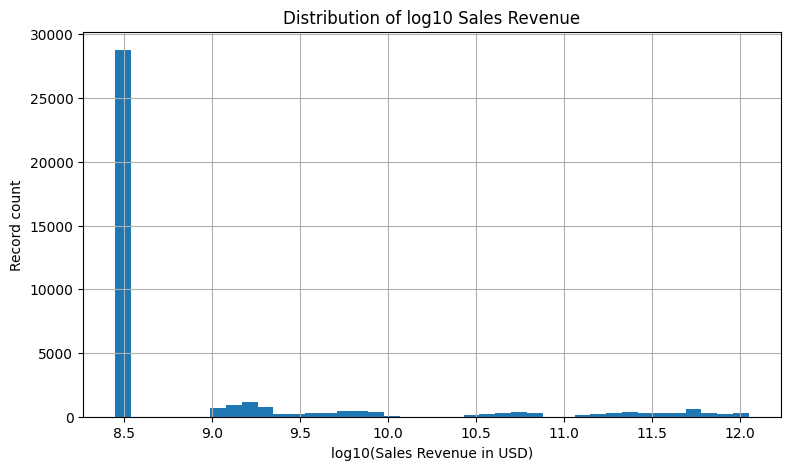

In [17]:

numeric_cols = [
    "Units Sold", "Customer Satisfaction", "Marketing Spend (USD)",
    "Discount Percentage (%)", "Return Rate (%)", "AI/ML Adoption Rate (%)",
    "Ad Campaign Effectiveness", "Customer Retention Rate (%)", "Market Share (%)",
    "Date_Year", "Date_Month"
]
categorical_cols = [
    "Product Category", "Product Name", "Region", "Customer Segment",
    "Customer Type", "Competitor Influence", "Competitor Product"
]

display(df[numeric_cols + ["Sales Revenue (USD)"]].describe().T)
print("Categorical columns:", categorical_cols)
print("Numeric columns:", numeric_cols + ["Sales Revenue (USD)"])
print("Product category counts:")
display(df["Product Category"].value_counts().to_frame("Records"))

plt.figure()
plt.hist(np.log10(df["Sales Revenue (USD)"].clip(lower=1)), bins=40)
plt.title("Distribution of log10 Sales Revenue")
plt.xlabel("log10(Sales Revenue in USD)")
plt.ylabel("Record count")
plt.show()

,Units Sold,Customer Satisfaction,Marketing Spend (USD),Discount Percentage (%),Return Rate (%),AI/ML Adoption Rate (%),Ad Campaign Effectiveness,Customer Retention Rate (%),Market Share (%),Sales Revenue (USD)
Units Sold,1.000,0.003,0.003,0.004,-0.001,-0.002,0.000,-0.002,0.002,-0.001
Customer Satisfaction,0.003,1.000,0.007,0.008,-0.005,0.003,0.012,0.011,-0.008,-0.001
Marketing Spend (USD),0.003,0.007,1.000,0.000,-0.003,0.003,0.006,-0.005,-0.006,-0.001
Discount Percentage (%),0.004,0.008,0.000,1.000,-0.006,-0.004,0.004,0.005,0.004,-0.006
Return Rate (%),-0.001,-0.005,-0.003,-0.006,1.000,0.008,-0.003,-0.002,-0.002,0.001
AI/ML Adoption Rate (%),-0.002,0.003,0.003,-0.004,0.008,1.000,0.005,0.011,0.001,-0.004
Ad Campaign Effectiveness,0.000,0.012,0.006,0.004,-0.003,0.005,1.000,-0.004,0.002,-0.002
Customer Retention Rate (%),-0.002,0.011,-0.005,0.005,-0.002,0.011,-0.004,1.000,-0.003,-0.002
Market Share (%),0.002,-0.008,-0.006,0.004,-0.002,0.001,0.002,-0.003,1.000,-0.000
Sales Revenue (USD),-0.001,-0.001,-0.001,-0.006,0.001,-0.004,-0.002,-0.002,-0.000,1.000


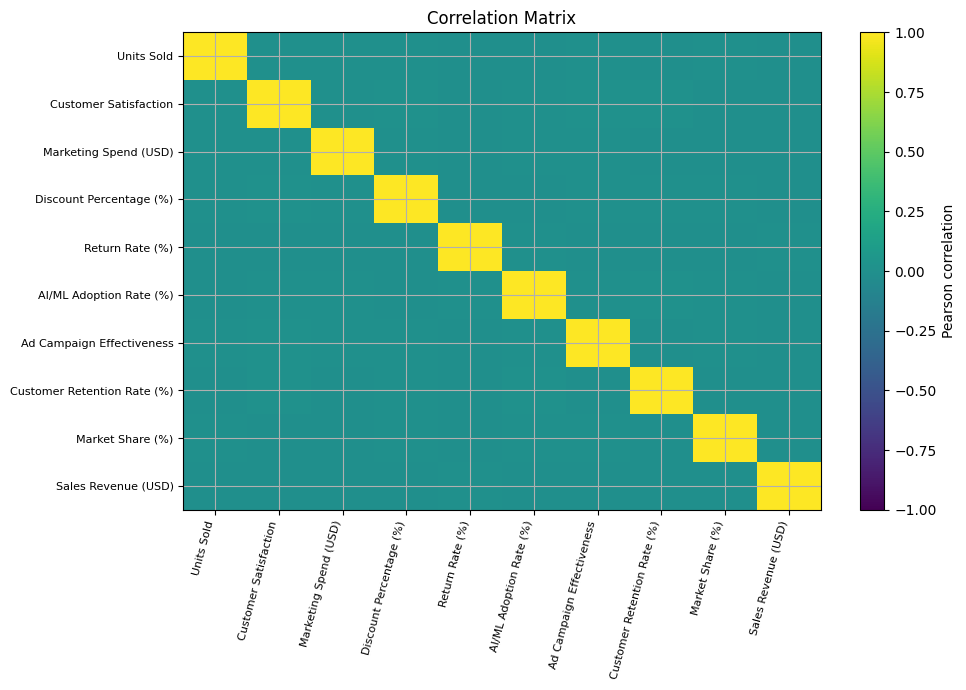

Correlation with sales revenue:


,Correlation
Sales Revenue (USD),1.000000
Return Rate (%),0.000872
Market Share (%),-0.000014
Customer Satisfaction,-0.000513
Units Sold,-0.000896
Marketing Spend (USD),-0.000990
Customer Retention Rate (%),-0.001545
Ad Campaign Effectiveness,-0.002271
AI/ML Adoption Rate (%),-0.003648
Discount Percentage (%),-0.005936


In [18]:

corr_cols = [
    "Units Sold", "Customer Satisfaction", "Marketing Spend (USD)",
    "Discount Percentage (%)", "Return Rate (%)", "AI/ML Adoption Rate (%)",
    "Ad Campaign Effectiveness", "Customer Retention Rate (%)",
    "Market Share (%)", "Sales Revenue (USD)"
]
corr = df[corr_cols].corr(numeric_only=True)
display(corr.round(3))

plt.figure(figsize=(10, 7))
plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=75, ha="right", fontsize=8)
plt.yticks(range(len(corr.columns)), corr.columns, fontsize=8)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

print("Correlation with sales revenue:")
display(corr["Sales Revenue (USD)"].sort_values(ascending=False).to_frame("Correlation"))

                            OLS Regression Results                            
Dep. Variable:      Log_Sales_Revenue   R-squared:                       0.370
Model:                            OLS   Adj. R-squared:                  0.370
Method:                 Least Squares   F-statistic:                     401.4
Date:                Sat, 10 Oct 2026   Prob (F-statistic):               0.00
Time:                        04:19:42   Log-Likelihood:                -77544.
No. Observations:               39298   AIC:                         1.552e+05
Df Residuals:                   39265   BIC:                         1.554e+05
Df Model:                          32                                         
Covariance Type:                  HC3                                         
                                                coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------

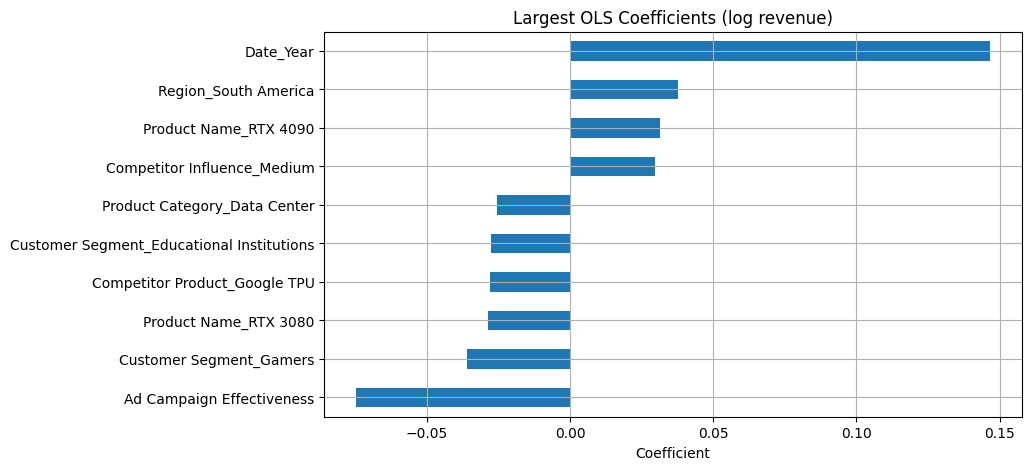

In [19]:

model_df = df[numeric_cols + categorical_cols + ["Log_Sales_Revenue", "High_Revenue"]].copy()
model_df = model_df.replace([np.inf, -np.inf], np.nan).dropna(subset=["Log_Sales_Revenue"])
X_ols = pd.get_dummies(model_df[numeric_cols + categorical_cols], drop_first=True, dtype=float)
X_ols = X_ols.replace([np.inf, -np.inf], np.nan)
X_ols = X_ols.fillna(X_ols.median(numeric_only=True)).fillna(0)
X_ols = sm.add_constant(X_ols, has_constant="add")
y_ols = model_df["Log_Sales_Revenue"].astype(float)

ols = sm.OLS(y_ols, X_ols).fit(cov_type="HC3")
print(ols.summary())
ols_pred = ols.predict(X_ols)
print("OLS in-sample R-squared:", round(ols.rsquared, 4))
print("OLS in-sample MAE (log scale):", round(mean_absolute_error(y_ols, ols_pred), 4))
print("OLS in-sample RMSE (log scale):", round(np.sqrt(mean_squared_error(y_ols, ols_pred)), 4))

coef = ols.params.drop("const", errors="ignore")
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).head(10).index)
top_coef.sort_values().plot(kind="barh", title="Largest OLS Coefficients (log revenue)")
plt.xlabel("Coefficient")
plt.show()

Test R-squared: 0.3837
Test MAE (log scale): 1.3569
Test RMSE (log scale): 1.7693


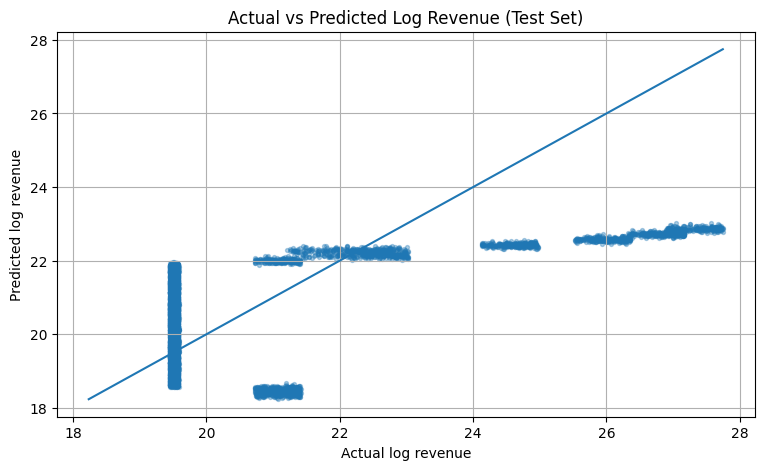

In [20]:

features = numeric_cols + categorical_cols
X = model_df[features].copy()
y = model_df["Log_Sales_Revenue"].astype(float)

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
reg_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", LinearRegression())
])
reg_model.fit(X_train, y_train)
y_pred = reg_model.predict(X_test)

print("Test R-squared:", round(r2_score(y_test, y_pred), 4))
print("Test MAE (log scale):", round(mean_absolute_error(y_test, y_pred), 4))
print("Test RMSE (log scale):", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))

plt.figure()
plt.scatter(y_test, y_pred, s=8, alpha=0.35)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims)
plt.xlabel("Actual log revenue")
plt.ylabel("Predicted log revenue")
plt.title("Actual vs Predicted Log Revenue (Test Set)")
plt.show()

Logistic accuracy: 0.6102
Logistic ROC-AUC: 0.6637
              precision    recall  f1-score   support

           0       0.61      0.60      0.61      3930
           1       0.61      0.62      0.61      3930

    accuracy                           0.61      7860
   macro avg       0.61      0.61      0.61      7860
weighted avg       0.61      0.61      0.61      7860

Decision Tree accuracy: 0.7682
Decision Tree ROC-AUC: 0.7671


,Feature,Importance
9,num__Date_Year,0.996491
0,num__Units Sold,0.001315
4,num__Return Rate (%),0.001037
2,num__Marketing Spend (USD),0.000598
19,cat__Product Name_Tesla V100,0.000559
1,num__Customer Satisfaction,0.000000
3,num__Discount Percentage (%),0.000000
6,num__Ad Campaign Effectiveness,0.000000
5,num__AI/ML Adoption Rate (%),0.000000
8,num__Market Share (%),0.000000


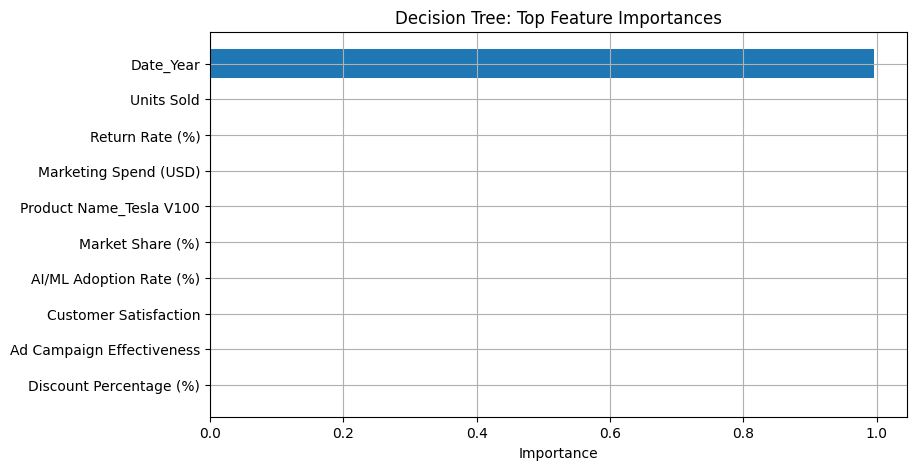

In [21]:

y_class = model_df["High_Revenue"].astype(int)
X_train_c, X_test_c, yc_train, yc_test = train_test_split(
    X, y_class, test_size=0.20, random_state=42, stratify=y_class
)

class_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

logistic = Pipeline([
    ("preprocess", class_preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
logistic.fit(X_train_c, yc_train)
log_pred = logistic.predict(X_test_c)
log_prob = logistic.predict_proba(X_test_c)[:, 1]
print("Logistic accuracy:", round(accuracy_score(yc_test, log_pred), 4))
print("Logistic ROC-AUC:", round(roc_auc_score(yc_test, log_prob), 4))
print(classification_report(yc_test, log_pred))

tree = Pipeline([
    ("preprocess", class_preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=50, random_state=42,
        class_weight="balanced"
    ))
])
tree.fit(X_train_c, yc_train)
tree_pred = tree.predict(X_test_c)
tree_prob = tree.predict_proba(X_test_c)[:, 1]
print("Decision Tree accuracy:", round(accuracy_score(yc_test, tree_pred), 4))
print("Decision Tree ROC-AUC:", round(roc_auc_score(yc_test, tree_prob), 4))

feature_names = tree.named_steps["preprocess"].get_feature_names_out()
importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tree.named_steps["model"].feature_importances_
}).sort_values("Importance", ascending=False)
display(importance.head(10))

top_imp = importance.head(10).sort_values("Importance")
plt.barh(top_imp["Feature"].str.replace("num__", "", regex=False).str.replace("cat__", "", regex=False),
         top_imp["Importance"])
plt.title("Decision Tree: Top Feature Importances")
plt.xlabel("Importance")
plt.show()

Decision Tree accuracy: 0.7682


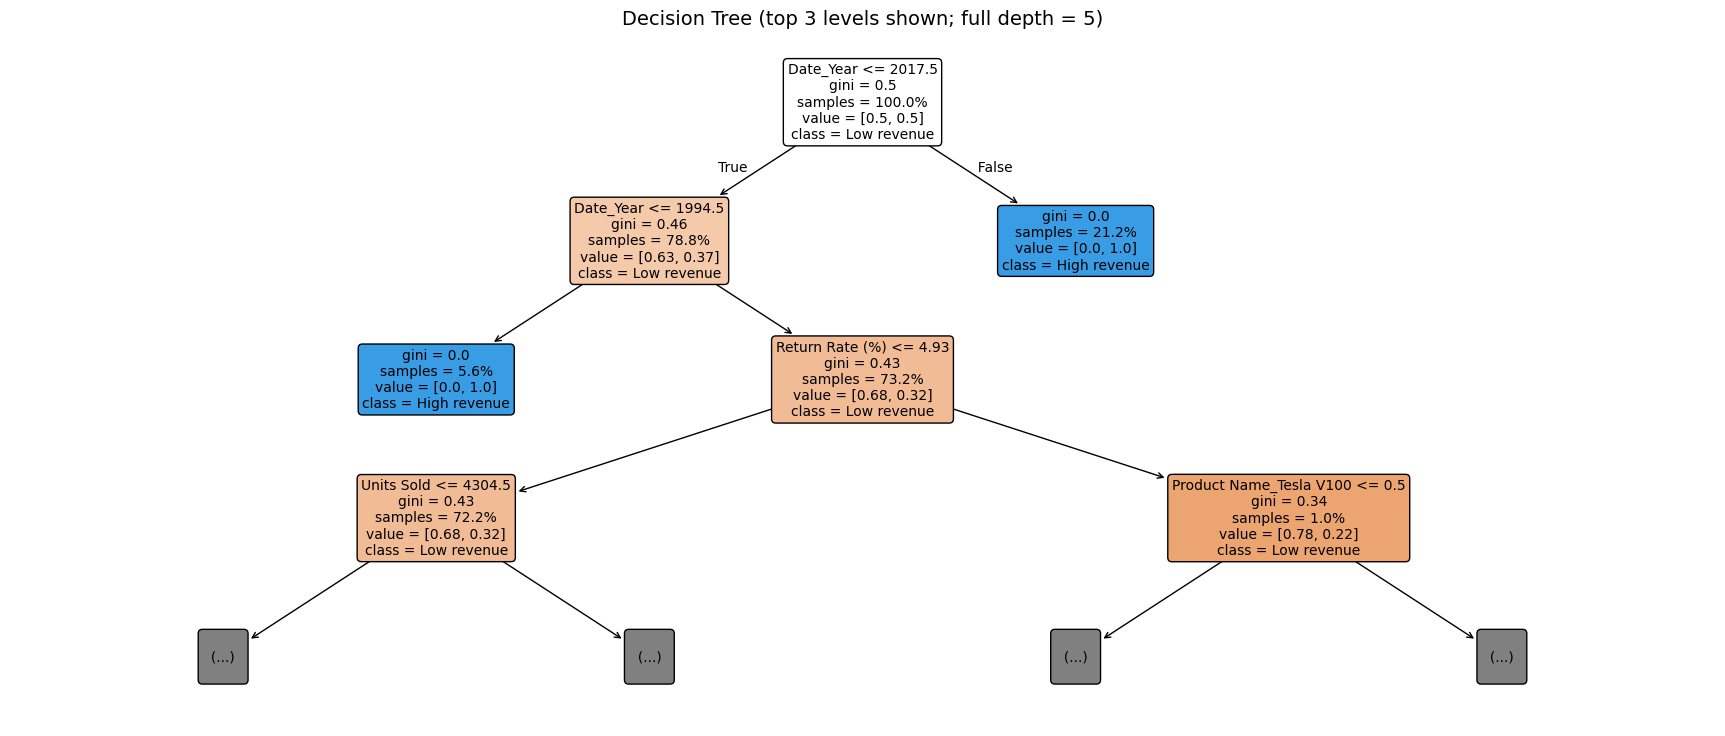

|--- Date_Year <= 2017.50
|   |--- Date_Year <= 1994.50
|   |   |--- class: 1
|   |--- Date_Year >  1994.50
|   |   |--- Return Rate (%) <= 4.93
|   |   |   |--- Units Sold <= 4304.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Units Sold >  4304.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- Return Rate (%) >  4.93
|   |   |   |--- Product Name_Tesla V100 <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Product Name_Tesla V100 >  0.50
|   |   |   |   |--- class: 0
|--- Date_Year >  2017.50
|   |--- class: 1



In [22]:

from sklearn.tree import plot_tree, export_text

pre_raw = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])
tree_vis = Pipeline([
    ("preprocess", pre_raw),
    ("model", DecisionTreeClassifier(max_depth=5, min_samples_leaf=50,
                                     random_state=42, class_weight="balanced"))
])
tree_vis.fit(X_train_c, yc_train)
vis_pred = tree_vis.predict(X_test_c)
print("Decision Tree accuracy:", round(accuracy_score(yc_test, vis_pred), 4))

names = [n.replace("num__", "").replace("cat__", "")
         for n in tree_vis.named_steps["preprocess"].get_feature_names_out()]

fig, ax = plt.subplots(figsize=(22, 9))
ax.grid(False)
plot_tree(tree_vis.named_steps["model"], feature_names=names,
          class_names=["Low revenue", "High revenue"],
          filled=True, rounded=True, max_depth=3,
          fontsize=10, proportion=True, precision=2, ax=ax)
ax.set_title("Decision Tree (top 3 levels shown; full depth = 5)", fontsize=14)
plt.savefig("decision_tree.png", dpi=170, bbox_inches="tight")
plt.show()


print(export_text(tree_vis.named_steps["model"], feature_names=names, max_depth=3))

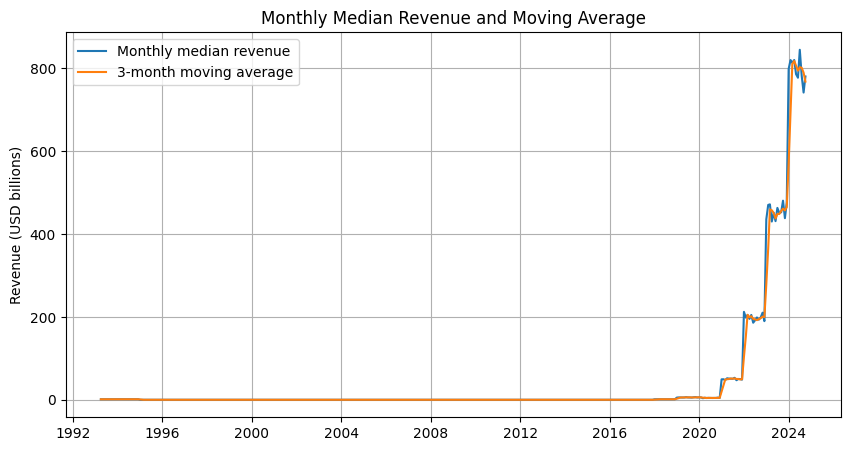

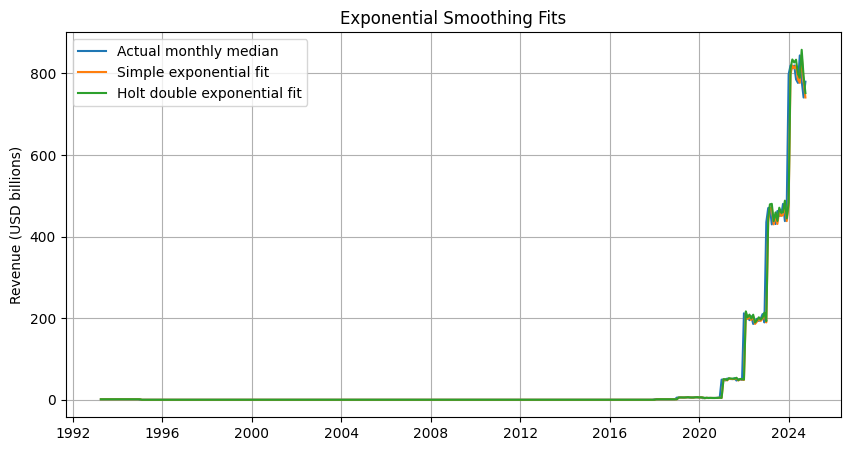

,MAE,RMSE
3-month Moving Average,3.090296e+09,1.821878e+10
Simple Exponential Smoothing,3.960510e+09,2.401600e+10
Holt Double Exponential,4.037493e+09,2.382019e+10


In [23]:

monthly = (
    df.dropna(subset=["Date"])
      .groupby("Month")["Sales Revenue (USD)"]
      .median()
      .sort_index()
      .asfreq("MS")
)
monthly = monthly.interpolate(method="time").ffill().bfill()


moving_avg = monthly.rolling(window=3, min_periods=1).mean()


ses_fit = SimpleExpSmoothing(monthly, initialization_method="estimated").fit(optimized=True)


holt_fit = Holt(monthly, initialization_method="estimated").fit(optimized=True)

plt.figure(figsize=(10, 5))
plt.plot(monthly.index, monthly / 1e9, label="Monthly median revenue")
plt.plot(moving_avg.index, moving_avg / 1e9, label="3-month moving average")
plt.ylabel("Revenue (USD billions)")
plt.title("Monthly Median Revenue and Moving Average")
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(monthly.index, monthly / 1e9, label="Actual monthly median")
plt.plot(ses_fit.fittedvalues.index, ses_fit.fittedvalues / 1e9, label="Simple exponential fit")
plt.plot(holt_fit.fittedvalues.index, holt_fit.fittedvalues / 1e9, label="Holt double exponential fit")
plt.ylabel("Revenue (USD billions)")
plt.title("Exponential Smoothing Fits")
plt.legend()
plt.show()


actual_eval = monthly.iloc[3:]
ma_eval = moving_avg.iloc[3:]
ses_eval = ses_fit.fittedvalues.iloc[3:]
holt_eval = holt_fit.fittedvalues.iloc[3:]

def error_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }

error_table = pd.DataFrame({
    "3-month Moving Average": error_metrics(actual_eval, ma_eval),
    "Simple Exponential Smoothing": error_metrics(actual_eval, ses_eval),
    "Holt Double Exponential": error_metrics(actual_eval, holt_eval)
}).T
display(error_table.round(2))

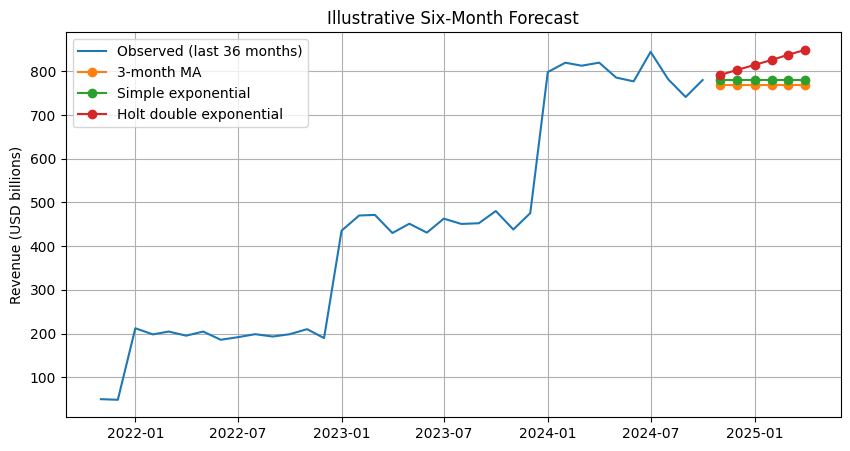

Last observed month: 2024-10-01
Mean 6-month MA forecast: 767519499733.9
Mean 6-month SES forecast: 779794013254.59
Mean 6-month Holt forecast: 820164605356.51
Caution: the dataset is irregular/synthetic and contains extreme values; do not interpret forecasts as actual NVIDIA guidance.


In [24]:

horizon = 6
future_dates = pd.date_range(monthly.index[-1] + pd.offsets.MonthBegin(1), periods=horizon, freq="MS")
ma_forecast = pd.Series([monthly.iloc[-3:].mean()] * horizon, index=future_dates)
ses_forecast = ses_fit.forecast(horizon)
holt_forecast = holt_fit.forecast(horizon)

plt.figure(figsize=(10, 5))
plt.plot(monthly.index[-36:], monthly.iloc[-36:] / 1e9, label="Observed (last 36 months)")
plt.plot(future_dates, ma_forecast / 1e9, marker="o", label="3-month MA")
plt.plot(future_dates, ses_forecast / 1e9, marker="o", label="Simple exponential")
plt.plot(future_dates, holt_forecast / 1e9, marker="o", label="Holt double exponential")
plt.ylabel("Revenue (USD billions)")
plt.title("Illustrative Six-Month Forecast")
plt.legend()
plt.show()

print("Last observed month:", monthly.index[-1].date())
print("Mean 6-month MA forecast:", round(ma_forecast.mean(), 2))
print("Mean 6-month SES forecast:", round(ses_forecast.mean(), 2))
print("Mean 6-month Holt forecast:", round(holt_forecast.mean(), 2))
print("Caution: the dataset is irregular/synthetic and contains extreme values; do not interpret forecasts as actual NVIDIA guidance.")